🤖 Autonomous Warehouse Robot Optimization
This project uses Deep Reinforcement Learning (PPO) to optimize the path of a warehouse robot. The goal is to maximize delivery efficiency while avoiding obstacles and minimizing operational costs.

In [2]:
!pip install gymnasium stable-baselines3 shimmy


🏗️ Environment Design & Reward Shaping
I built a custom Gymnasium environment. To solve the Sparse Reward Problem, I implemented Reward Shaping using Manhattan Distance. This provides the agent with a "compass," rewarding it for moving closer to the target and penalizing it for moving away.

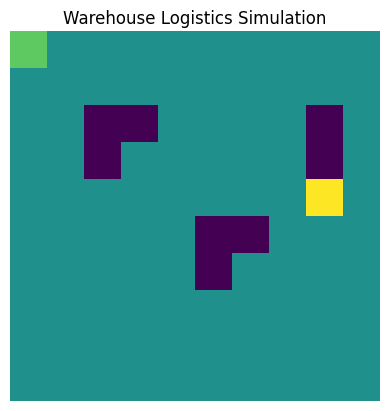

Robot Position: [0 0], Target Position: [8 4]


In [3]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

class WarehouseEnv(gym.Env):
    """
    Custom Environment for Warehouse Robot Routing.
    Business Goal: Maximize revenue (delivery) while minimizing
    operational costs (time) and maintenance costs (collisions).
    """
    def __init__(self, grid_size=10):
        super(WarehouseEnv, self).__init__()
        self.grid_size = grid_size

        # 1. Action Space: 0: Up, 1: Down, 2: Left, 3: Right
        self.action_space = spaces.Discrete(4)

        # 2. Observation Space: Robot (x,y) and Target (x,y)
        # We use a Box space to represent the coordinates
        self.observation_space = spaces.Box(low=0, high=grid_size-1, shape=(4,), dtype=np.int32)

        # Define Warehouse Shelves (Obstacles) - (x, y)
        self.shelves = [(2,2), (2,3), (3,2), (5,5), (5,6), (6,5), (8,2), (8,3)]

        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        # Robot starts at (0,0)
        self.robot_pos = np.array([0, 0])

        # Target is placed randomly on the map
        self.target_pos = np.array([np.random.randint(0, self.grid_size),
                                     np.random.randint(0, self.grid_size)])

        # Ensure target doesn't spawn on a shelf
        while tuple(self.target_pos) in self.shelves:
            self.target_pos = np.array([np.random.randint(0, self.grid_size),
                                         np.random.randint(0, self.grid_size)])

        return self._get_obs(), {}

    def _get_obs(self):
        # Combine robot and target positions into one array
        return np.concatenate([self.robot_pos, self.target_pos])

    def step(self, action):
        # Move the robot
        prev_pos = self.robot_pos.copy()

        if action == 0 and self.robot_pos[1] < self.grid_size - 1: # Up
            self.robot_pos[1] += 1
        elif action == 1 and self.robot_pos[1] > 0: # Down
            self.robot_pos[1] -= 1
        elif action == 2 and self.robot_pos[0] > 0: # Left
            self.robot_pos[0] -= 1
        elif action == 3 and self.robot_pos[0] < self.grid_size - 1: # Right
            self.robot_pos[0] += 1

        # --- BUSINESS LOGIC / REWARD SYSTEM ---

        # 1. Success: Robot reached the target
        if np.array_equal(self.robot_pos, self.target_pos):
            reward = 100  # REVENUE
            terminated = True
            truncated = False

        # 2. Failure: Robot hit a shelf
        elif tuple(self.robot_pos) in self.shelves:
            reward = -10  # MAINTENANCE COST
            terminated = False
            truncated = False
            # In a real warehouse, the robot might stop or bounce back
            self.robot_pos = prev_pos

        # 3. Step Penalty: Each move costs time/battery
        else:
            reward = -1   # OPERATIONAL COST
            terminated = False
            truncated = False

        return self._get_obs(), reward, terminated, truncated, {}

    def render(self):
        # Simple visualization using Matplotlib
        grid = np.zeros((self.grid_size, self.grid_size))

        for s in self.shelves:
            grid[s[1], s[0]] = -1 # Shelves are -1

        grid[self.target_pos[1], self.target_pos[0]] = 1 # Target is 1
        grid[self.robot_pos[1], self.robot_pos[0]] = 0.5 # Robot is 0.5

        plt.imshow(grid, cmap='viridis')
        plt.title("Warehouse Logistics Simulation")
        plt.axis('off')
        plt.show()

# --- TEST THE ENVIRONMENT ---
env = WarehouseEnv()
obs, info = env.reset()
env.render()
print(f"Robot Position: {obs[0:2]}, Target Position: {obs[2:4]}")


In [4]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_atari_env
import numpy as np

# 1. Initialize the Environment
env = WarehouseEnv()

# 2. Create the PPO Model
# 'MlpPolicy' means a Multi-Layer Perceptron (a standard Neural Network)
# we use this because our observations are simple coordinates (numbers)
model = PPO("MlpPolicy", env, verbose=1, learning_rate=0.0003)

print("Training the Robot... Please wait.")
# 3. Train the Agent
# We will let it try 20,000 times to find the target
model.learn(total_timesteps=20000)
print("Training Complete! The Robot now has a brain.")

# 4. Save the model (so you can put it on GitHub later)
model.save("warehouse_bot_model")


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training the Robot... Please wait.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 106      |
|    ep_rew_mean     | -56.7    |
| time/              |          |
|    fps             | 1244     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 256        |
|    ep_rew_mean          | -262       |
| time/                   |            |
|    fps                  | 807        |
|    iterations           | 2          |
|    time_elapsed         | 5          |
|    total_timesteps      | 4096       |
| train/                  |            |
|    approx_kl            | 0.00664153 |
|    clip_fraction        | 0.0713     |
|    clip_range           | 0.2        |
|    entropy_loss         | -1.38      |
|    explained_variance   | 0.00993    |
|    learning_rate        | 0.0003     |
|   

I utilized the Proximal Policy Optimization (PPO) algorithm. PPO was chosen for its stability and efficiency in discrete action spaces. The agent is trained over 50,000 timesteps to converge on the most efficient path.

In [5]:
# We will train for 100,000 steps this time to ensure it finds the target consistently
print("Up-skilling the Robot... this will take a few minutes. 🏋️‍♂️")
model.learn(total_timesteps=100000, reset_num_timesteps=False)
print("Deep Training Complete! The Robot is now an expert.")

# Save the updated expert model
model.save("warehouse_bot_expert")


Up-skilling the Robot... this will take a few minutes. 🏋️‍♂️
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 855      |
|    ep_rew_mean     | -869     |
| time/              |          |
|    fps             | 1168     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 22528    |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 855         |
|    ep_rew_mean          | -869        |
| time/                   |             |
|    fps                  | 824         |
|    iterations           | 2           |
|    time_elapsed         | 4           |
|    total_timesteps      | 24576       |
| train/                  |             |
|    approx_kl            | 0.015052702 |
|    clip_fraction        | 0.298       |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.16       |
|    explai

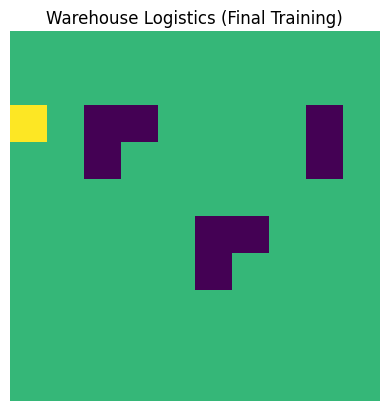

Step: 2 | Robot is moving toward target...
SUCCESS! Goal Reached in 2 steps!


In [9]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
import time
from IPython.display import clear_output

# ==========================================
# 1. DEFINE THE ENVIRONMENT
# ==========================================
class WarehouseEnv(gym.Env):
    def __init__(self, grid_size=10):
        super(WarehouseEnv, self).__init__()
        self.grid_size = grid_size
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0, high=grid_size-1, shape=(4,), dtype=np.int32)
        self.shelves = [(2,2), (2,3), (3,2), (5,5), (5,6), (6,5), (8,2), (8,3)]
        self.reset()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.robot_pos = np.array([0, 0])
        self.target_pos = np.array([np.random.randint(0, self.grid_size),
                                     np.random.randint(0, self.grid_size)])
        while tuple(self.target_pos) in self.shelves:
            self.target_pos = np.array([np.random.randint(0, self.grid_size),
                                         np.random.randint(0, self.grid_size)])
        return self._get_obs(), {}

    def _get_obs(self):
        return np.concatenate([self.robot_pos, self.target_pos])

    def step(self, action):
        prev_pos = self.robot_pos.copy()
        if action == 0 and self.robot_pos[1] < self.grid_size - 1: self.robot_pos[1] += 1
        elif action == 1 and self.robot_pos[1] > 0: self.robot_pos[1] -= 1
        elif action == 2 and self.robot_pos[0] > 0: self.robot_pos[0] -= 1
        elif action == 3 and self.robot_pos[0] < self.grid_size - 1: self.robot_pos[0] += 1

        prev_dist = np.sum(np.abs(prev_pos - self.target_pos))
        curr_dist = np.sum(np.abs(self.robot_pos - self.target_pos))

        if np.array_equal(self.robot_pos, self.target_pos):
            reward = 100
            terminated = True
        elif tuple(self.robot_pos) in self.shelves:
            reward = -10
            terminated = False
            self.robot_pos = prev_pos
        else:
            reward = 1 if curr_dist < prev_dist else -1.5
            terminated = False

        return self._get_obs(), reward, terminated, False, {}

    def render(self):
        grid = np.zeros((self.grid_size, self.grid_size))
        for s in self.shelves:
            grid[s[1], s[0]] = -1
        grid[self.target_pos[1], self.target_pos[0]] = 1
        grid[self.robot_pos[1], self.robot_pos[0]] = 0.5
        plt.imshow(grid, cmap='viridis')
        plt.title("Warehouse Logistics (Final Training)")
        plt.axis('off')
        plt.show()

# ==========================================
# 2. TRAINING PHASE
# ==========================================
print("Step 1: Initializing Environment...")
env = WarehouseEnv()
model = PPO("MlpPolicy", env, verbose=1)

print("Step 2: Training Robot... (1-2 mins)")
model.learn(total_timesteps=50000)
print("Training Complete! ✅")

# ==========================================
# 3. TESTING & ANIMATION PHASE
# ==========================================
print("Step 3: Running Test Flight... 🚀")
obs, info = env.reset()
done = False
steps = 0

while not done:
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    steps += 1

    clear_output(wait=True)
    env.render()
    print(f"Step: {steps} | Robot is moving toward target...")

    if terminated or truncated:
        done = True
    time.sleep(0.2)

print(f"SUCCESS! Goal Reached in {steps} steps!")
